In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    ConfusionMatrixDisplay)

In [2]:
df=pd.read_csv("/Users/nidagallusandeep/Downloads/loan_approval_20000_rows.csv")

In [3]:
df.head()

,applicant_id,age,gender,education,employment_status,annual_income,credit_score,loan_amount,loan_term_months,existing_loans,home_ownership,loan_purpose,debt_to_income_ratio,loan_approved
0,APP00001,22,Male,Bachelor,Unemployed,85101.41,639.0,62024.62,36,0,Own,Medical,75.00,0
1,APP00002,59,Male,Bachelor,Full-time,12558.69,756.0,1000.00,24,1,Mortgage,Home improvement,14.29,1
2,APP00003,52,Female,PhD,Part-time,56825.83,621.0,33741.65,60,1,Mortgage,Home improvement,67.67,0
3,APP00004,41,Female,High School,Full-time,55990.36,707.0,32826.51,24,1,Rent,Education,75.00,0
4,APP00005,40,Female,High School,Full-time,54782.02,635.0,9227.51,36,0,Rent,Vehicle,40.15,0


In [4]:
df.shape

(20000, 14)

In [5]:
df.columns

Index(['applicant_id', 'age', 'gender', 'education', 'employment_status',
       'annual_income', 'credit_score', 'loan_amount', 'loan_term_months',
       'existing_loans', 'home_ownership', 'loan_purpose',
       'debt_to_income_ratio', 'loan_approved'],
      dtype='object')

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   applicant_id          20000 non-null  object 
 1   age                   20000 non-null  int64  
 2   gender                20000 non-null  object 
 3   education             20000 non-null  object 
 4   employment_status     19602 non-null  object 
 5   annual_income         19645 non-null  float64
 6   credit_score          19599 non-null  float64
 7   loan_amount           20000 non-null  float64
 8   loan_term_months      20000 non-null  int64  
 9   existing_loans        20000 non-null  int64  
 10  home_ownership        19595 non-null  object 
 11  loan_purpose          20000 non-null  object 
 12  debt_to_income_ratio  20000 non-null  float64
 13  loan_approved         20000 non-null  int64  
dtypes: float64(4), int64(4), object(6)
memory usage: 2.1+ MB


In [7]:
df.describe()

,age,annual_income,credit_score,loan_amount,loan_term_months,existing_loans,debt_to_income_ratio,loan_approved
count,20000.000000,19645.000000,19599.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000
mean,43.812500,64810.879983,679.030716,28549.809559,41.542800,1.193300,57.330941,0.184150
std,15.272469,22000.472073,64.707451,17887.568616,14.926504,1.095397,17.905816,0.387616
min,18.000000,12000.000000,431.000000,1000.000000,12.000000,0.000000,2.310000,0.000000
25%,31.000000,49846.260000,635.000000,14470.527500,36.000000,0.000000,43.130000,0.000000
50%,44.000000,64574.510000,679.000000,25689.415000,36.000000,1.000000,61.645000,0.000000
75%,57.000000,79727.100000,723.000000,40151.302500,60.000000,2.000000,75.000000,0.000000
max,70.000000,153623.630000,850.000000,100000.000000,60.000000,6.000000,75.000000,1.000000


In [8]:
df.isnull().sum()

applicant_id              0
age                       0
gender                    0
education                 0
employment_status       398
annual_income           355
credit_score            401
loan_amount               0
loan_term_months          0
existing_loans            0
home_ownership          405
loan_purpose              0
debt_to_income_ratio      0
loan_approved             0
dtype: int64

In [9]:
df["employment_status"]=df["employment_status"].fillna(df["employment_status"].mode()[0])
df["annual_income"]=df["annual_income"].fillna(df["annual_income"].mean())
df["credit_score"]=df["credit_score"].fillna(df["credit_score"].mean())
df["home_ownership"]=df["home_ownership"].fillna(df["home_ownership"].mode()[0])

In [10]:
df.isnull().sum()

applicant_id            0
age                     0
gender                  0
education               0
employment_status       0
annual_income           0
credit_score            0
loan_amount             0
loan_term_months        0
existing_loans          0
home_ownership          0
loan_purpose            0
debt_to_income_ratio    0
loan_approved           0
dtype: int64

In [11]:
df.duplicated().sum()

np.int64(0)

In [12]:
X = df.drop(columns=["applicant_id", "loan_approved"])
y = df["loan_approved"]

In [13]:
numeric_features = [
    "age",
    "annual_income",
    "credit_score",
    "loan_amount",
    "loan_term_months",
    "existing_loans",
    "debt_to_income_ratio"]

categorical_features = [
    "gender",
    "education",
    "employment_status",
    "home_ownership",
    "loan_purpose"]

In [14]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.20,random_state=42,stratify=y)
print(X_train.shape)
print(X_test.shape)

(16000, 12)
(4000, 12)


# Apply Encoding and Scaling

In [15]:
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)])

# Train Random Forest Model

In [16]:
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        random_state=42,
        n_jobs=-1))])
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](12,)","['age','gender','education',...,'home_ownership','loan_purpose', 'debt_to_income_ratio']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,12
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying

In [17]:
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

In [18]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall:", recall_score(y_test, y_pred, zero_division=0))
print("F1 Score:", f1_score(y_test, y_pred, zero_division=0))
print("ROC-AUC:", roc_auc_score(y_test, y_prob))

Accuracy: 0.83525
Precision: 0.6181818181818182
Recall: 0.276797829036635
F1 Score: 0.3823805060918463
ROC-AUC: 0.7982294805747265


In [19]:
param_grid = {
    "classifier__n_estimators": [100, 200, 300],
    "classifier__max_depth": [None, 10, 20],
    "classifier__min_samples_split": [2, 5, 10],
    "classifier__min_samples_leaf": [1, 2, 4],
    "classifier__max_features": ["sqrt", "log2"]}
search = RandomizedSearchCV(
    estimator=model,
    param_distributions=param_grid,
    n_iter=10,
    scoring="f1",
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=1)
search.fit(X_train, y_train)

Fitting 3 folds for each of 10 candidates, totalling 30 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'classifier__max_depth': [None, 10, ...], 'classifier__max_features': ['sqrt', 'log2'], 'classifier__min_samples_leaf': [1, 2, ...], 'classifier__min_samples_split': [2, 5, ...], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",10
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estima

In [20]:
best_model = search.best_estimator_
print("Best Parameters:")
print(search.best_params_)
print("Best CV F1 Score:", search.best_score_)

Best Parameters:
{'classifier__n_estimators': 200, 'classifier__min_samples_split': 2, 'classifier__min_samples_leaf': 1, 'classifier__max_features': 'sqrt', 'classifier__max_depth': 20}
Best CV F1 Score: 0.40675287613037286


# Evaluate Evaluated model

In [22]:
y_pred_tuned = best_model.predict(X_test)
y_prob_tuned = best_model.predict_proba(X_test)[:, 1]

print("Accuracy:", accuracy_score(y_test, y_pred_tuned))
print("Precision:", precision_score(y_test, y_pred_tuned, zero_division=0))
print("Recall:", recall_score(y_test, y_pred_tuned, zero_division=0))
print("F1 Score:", f1_score(y_test, y_pred_tuned, zero_division=0))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_tuned))

Accuracy: 0.83825
Precision: 0.6363636363636364
Recall: 0.28493894165535955
F1 Score: 0.3936269915651359
ROC-AUC: 0.8083152204874271


In [24]:
print(classification_report(y_test, y_pred_tuned, zero_division=0))

              precision    recall  f1-score   support

           0       0.86      0.96      0.91      3263
           1       0.64      0.28      0.39       737

    accuracy                           0.84      4000
   macro avg       0.75      0.62      0.65      4000
weighted avg       0.82      0.84      0.81      4000



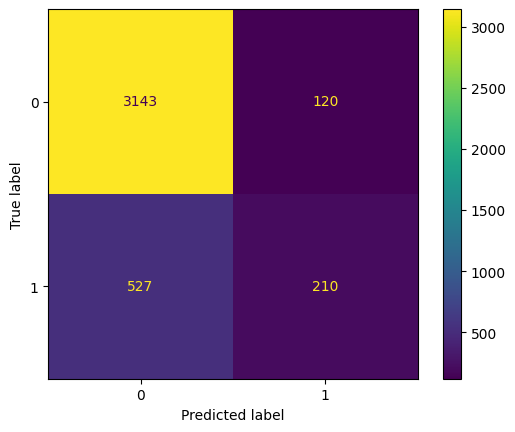

In [25]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_tuned)
plt.show()

# Predict for a a new applicant

In [26]:
new_applicant = pd.DataFrame([{
    "age": 32,
    "gender": "Female",
    "education": "Bachelor",
    "employment_status": "Full-time",
    "annual_income": 72000,
    "credit_score": 720,
    "loan_amount": 18000,
    "loan_term_months": 36,
    "existing_loans": 1,
    "home_ownership": "Rent",
    "loan_purpose": "Vehicle",
    "debt_to_income_ratio": 24.5
}])

In [28]:
prediction = best_model.predict(new_applicant)[0]
probability = best_model.predict_proba(new_applicant)[0, 1]

print("Prediction:", "Approved" if prediction == 1 else "Not Approved")
print(f"Estimated probability: {probability:.2%}")

Prediction: Approved
Estimated probability: 68.76%


In [29]:
joblib.dump(best_model, "loan_approval_random_forest.pkl")
print("Model saved successfully!")

Model saved successfully!
